# Week 8 — Wave Transformation I: Shoaling & Refraction

**OE 754 / 854 — Ocean Waves & Tides**

Consider a deep-water wave $(T, H_0, \theta_0)$ approaching a shoreline with known bathymetry. What is the wave height and direction at any depth $h$? Two conservation laws answer it:

$$E\,C_g\,b \;=\; \text{constant along a ray} \quad \text{(energy flux)}, \qquad k\sin\theta \;=\; \text{constant} \quad \text{(Snell's law for parallel contours)}.$$

Together they give

$$H = H_0 \cdot K_s \cdot K_r, \qquad K_s = \sqrt{\frac{C_{g,0}}{C_g}}, \qquad K_r = \sqrt{\frac{\cos\theta_0}{\cos\theta}}.$$

This notebook codes the inshore-calculation recipe from lecture. We apply it to a uniform-slope beach, then trace rays numerically over curved bathymetry.

### Goals

1. Code the inshore recipe as a function. Apply it over a sweep of depths for a normally-incident swell.
2. Add oblique incidence and show how $K_r$ changes the height profile.
3. Integrate a wave ray across a 2D depth field with a submarine shoal and watch the ray bend.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

import figure_style as fs

g = 9.81

## 1. The inshore-calculation recipe

Code it as in the lecture:

1. Deep-water values: $L_0 = gT^2/(2\pi)$, $C_0 = gT/(2\pi)$, $C_{g,0} = C_0/2$.
2. Solve dispersion at depth $h$ to get $k$, $L$, $C$, $C_g$.
3. Snell: $\theta = \arcsin((C/C_0)\sin\theta_0)$.
4. Coefficients: $K_s = \sqrt{C_0/(2C_g)}$, $K_r = \sqrt{\cos\theta_0/\cos\theta}$.
5. Local height: $H = H_0 K_s K_r$.


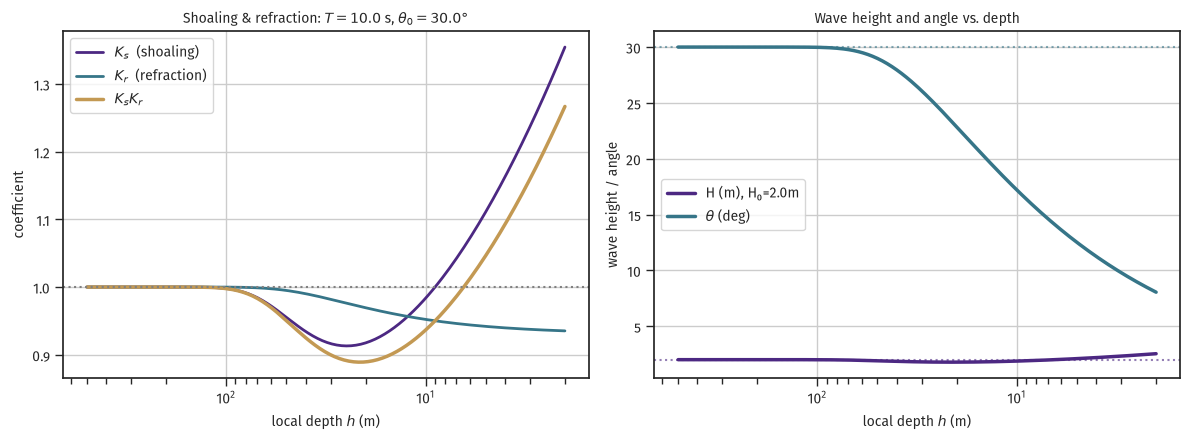

In [2]:
def solve_k(omega, h, tol=1e-12):
    k = omega**2 / g
    for _ in range(50):
        tkh = np.tanh(k*h)
        f = omega**2 - g*k*tkh
        fp = -g*tkh - g*h*k*(1-tkh**2)
        dk = f/fp; k -= dk
        if abs(dk) < tol: break
    return k


def inshore(T, H0, theta0_deg, h):
    # Inshore recipe; returns intermediate quantities
    omega = 2*np.pi/T
    # Deep water
    L0 = g*T**2 / (2*np.pi)
    C0 = L0/T
    Cg0 = C0/2
    # Local
    k = solve_k(omega, h)
    L = 2*np.pi/k
    C = L/T
    kh = k*h
    n = 0.5*(1 + 2*kh/np.sinh(2*kh))
    Cg = n*C
    # Snell
    theta0 = np.radians(theta0_deg)
    sin_theta = (C/C0) * np.sin(theta0)
    if np.any(np.abs(sin_theta) > 1):
        # past the critical angle (unphysical)
        theta = np.nan
    else:
        theta = np.arcsin(sin_theta)
    # Coefficients
    Ks = np.sqrt(Cg0 / Cg)
    Kr = np.sqrt(np.cos(theta0) / np.cos(theta))
    H = H0 * Ks * Kr
    return dict(k=k, L=L, C=C, Cg=Cg, kh=kh, theta_deg=np.degrees(theta),
                Ks=Ks, Kr=Kr, H=H)


# T = 10 s, H0 = 2 m, theta0 = 30 deg, h swept from deep to 2 m
T = 10.0
H0 = 2.0
theta0_deg = 30.0

h_sweep = np.logspace(np.log10(2.0), np.log10(500), 200)
Ks_arr = np.zeros_like(h_sweep)
Kr_arr = np.zeros_like(h_sweep)
H_arr  = np.zeros_like(h_sweep)
theta_arr = np.zeros_like(h_sweep)

for i, h in enumerate(h_sweep):
    r = inshore(T, H0, theta0_deg, h)
    Ks_arr[i] = r['Ks']; Kr_arr[i] = r['Kr']
    H_arr[i]  = r['H'];  theta_arr[i] = r['theta_deg']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.semilogx(h_sweep, Ks_arr, lw=2, color=fs.color_list[0], label=r'$K_s$  (shoaling)')
ax1.semilogx(h_sweep, Kr_arr, lw=2, color=fs.color_list[1], label=r'$K_r$  (refraction)')
ax1.semilogx(h_sweep, Ks_arr*Kr_arr, lw=2.5, color=fs.color_list[3], label=r'$K_s K_r$')
ax1.axhline(1.0, ls=':', color='0.5')
ax1.set_xlabel('local depth $h$ (m)')
ax1.set_ylabel('coefficient')
ax1.set_title(f'Shoaling & refraction: $T={T}$ s, $\\theta_0={theta0_deg}°$')
ax1.legend()
ax1.invert_xaxis()

ax2.semilogx(h_sweep, H_arr, lw=2.5, color=fs.color_list[0], label=f'H (m), H₀={H0}m')
ax2.semilogx(h_sweep, theta_arr, lw=2.5, color=fs.color_list[1], label=r'$\theta$ (deg)')
ax2.axhline(H0, ls=':', color=fs.color_list[0], alpha=0.6)
ax2.axhline(theta0_deg, ls=':', color=fs.color_list[1], alpha=0.6)
ax2.set_xlabel('local depth $h$ (m)')
ax2.set_ylabel('wave height / angle')
ax2.set_title('Wave height and angle vs. depth')
ax2.legend()
ax2.invert_xaxis()

plt.tight_layout()
plt.show()

Features to pick out:

- $K_s$ decreases slightly at first as the wave enters intermediate depth. Through the transition, $C_g$ rises above $C_{g,0}$, so $K_s < 1$. Near the shore, $C_g \to \sqrt{gh}$ and the denominator shrinks, so the coefficient rises sharply.
- $K_r$ decreases monotonically for oblique waves. Consider two rays crossing a fixed alongshore distance $\ell$. Their separation perpendicular to the crest is $b = \ell\cos\theta$. Refraction turns the wave toward shore-normal: $\theta$ falls, $\cos\theta$ rises, and $b$ widens. The same energy flux over a wider ray tube is less energy per unit crest length, so $K_r < 1$. That offsets some of the shoaling amplification. (Rays converge only where the contours themselves curve, over a headland, as in §3.)
- The angle $\theta$ decreases. The parts of the crest in deeper water move faster, so the wave bends toward the shore-normal. By $h = 2\,$m the original 30° swell is nearly perpendicular to the beach.

## 2. Headland and cove geometry

Rays converge on a headland, so wave energy concentrates and headlands erode. Rays diverge into a cove, so energy spreads and coves stay calm. A synthetic bathymetry to show it:

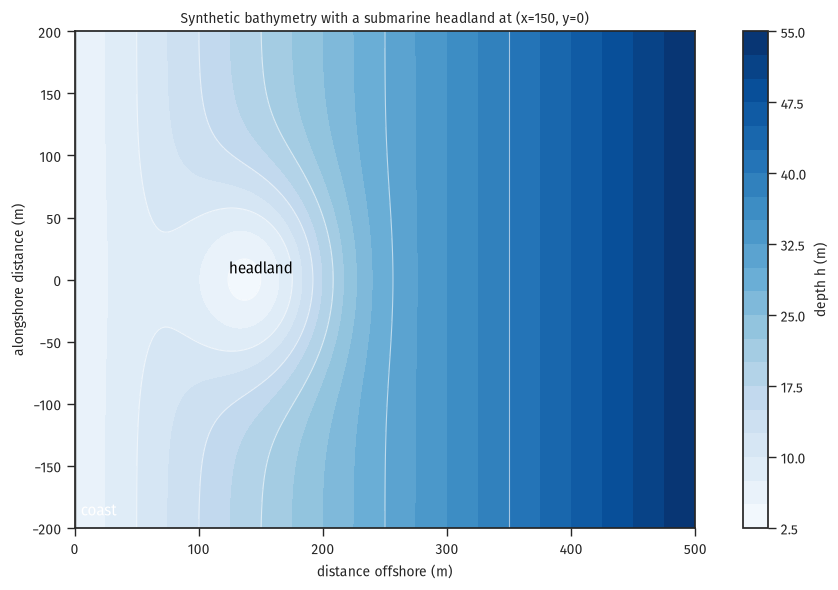

In [3]:
# Bathymetry with a headland bump at y = 0
xx = np.linspace(0, 500, 200)
yy = np.linspace(-200, 200, 200)
X, Y = np.meshgrid(xx, yy)
# Linear slope (shallow at x -> 0, deep at x -> 500) plus a Gaussian shoal
# near (x = 150, y = 0) as the headland
h_map = 5 + 50 * (X / 500)   # linear slope, m
headland = 15 * np.exp(-((Y)**2 / (80**2) + (X-150)**2 / (60**2)))
h_map = np.maximum(h_map - headland, 0.5)

fig, ax = plt.subplots(figsize=(10, 6))
cs = ax.contourf(X, Y, h_map, levels=20, cmap='Blues')
cbar = fig.colorbar(cs, ax=ax, label='depth h (m)')
# isobaths
ax.contour(X, Y, h_map, levels=[5, 10, 15, 20, 30, 40], colors='white', linewidths=0.8, alpha=0.6)
ax.fill_betweenx(yy, 0, 0.5*np.ones_like(yy), color='0.4', alpha=0.8)
ax.text(5, -190, 'coast', fontsize=11, color='white')
ax.text(150, 5, 'headland', fontsize=11, ha='center', color='black', rotation=0)
ax.set_xlabel('distance offshore (m)')
ax.set_ylabel('alongshore distance (m)')
ax.set_title('Synthetic bathymetry with a submarine headland at (x=150, y=0)')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

## 3. Numerical ray tracing

From the lecture, the ray-tracing ODE is:

$$\frac{dx}{ds} = \cos\theta, \qquad \frac{dy}{ds} = \sin\theta, \qquad
  \frac{d\theta}{ds} = \sin\theta\,\frac{1}{C}\frac{\partial C}{\partial x} - \cos\theta\,\frac{1}{C}\frac{\partial C}{\partial y}.$$

For a wave of period $T$, $C(x,y)$ comes from the dispersion relation at the local depth $h(x,y)$. Integrate forward from an offshore starting point.


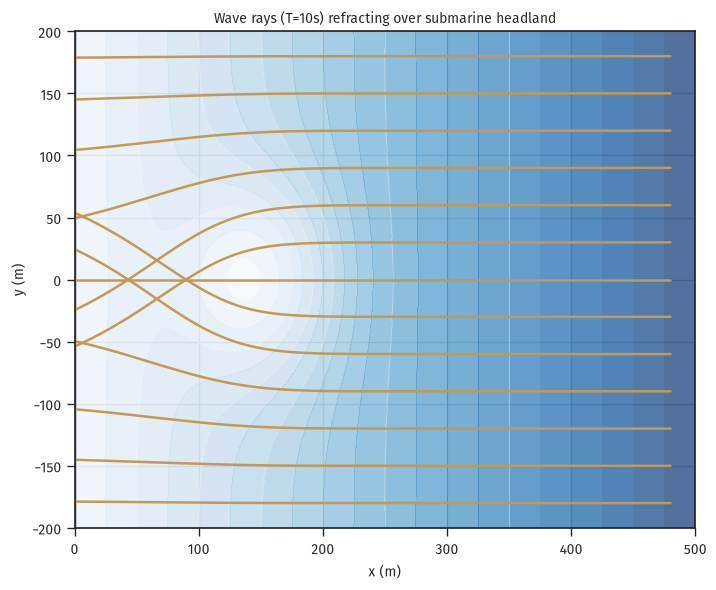

In [4]:
from scipy.interpolate import RegularGridInterpolator

# C(x,y) for a T = 10 s wave
T_ray = 10.0
omega = 2*np.pi/T_ray

# Vectorized Newton solve for k at every grid point
kh_map = np.zeros_like(h_map)
k_init = omega**2 / g * np.ones_like(h_map)
k_ = k_init.copy()
for _ in range(50):
    tkh = np.tanh(k_ * h_map)
    f_ = omega**2 - g*k_*tkh
    fp = -g*tkh - g*h_map*k_*(1-tkh**2)
    k_ -= f_/fp
C_map = omega / k_

C_interp = RegularGridInterpolator((yy, xx), C_map, bounds_error=False, fill_value=None)
dCdx = np.gradient(C_map, xx, axis=1)
dCdy = np.gradient(C_map, yy, axis=0)
dCdx_interp = RegularGridInterpolator((yy, xx), dCdx, bounds_error=False, fill_value=0)
dCdy_interp = RegularGridInterpolator((yy, xx), dCdy, bounds_error=False, fill_value=0)

def ray_ode(s, state):
    x, y, theta = state
    pt = (y, x)
    C_ = float(C_interp(pt))
    dCx = float(dCdx_interp(pt))
    dCy = float(dCdy_interp(pt))
    return [np.cos(theta),
            np.sin(theta),
            (np.sin(theta)*dCx - np.cos(theta)*dCy)/C_]


# Fan of rays launched shoreward from x = 480 m
fig, ax = plt.subplots(figsize=(10, 6))
ax.contourf(X, Y, h_map, levels=20, cmap='Blues', alpha=0.7)
ax.contour(X, Y, h_map, levels=[5, 10, 15, 20, 30, 40], colors='white', linewidths=0.8, alpha=0.5)
ax.fill_betweenx(yy, 0, 0.5*np.ones_like(yy), color='0.4', alpha=0.8)

y_starts = np.linspace(-180, 180, 13)
for y0 in y_starts:
    sol = solve_ivp(ray_ode, (0, 600), [480.0, y0, np.pi],
                    max_step=2.0, dense_output=False)
    # Clip at the coast
    inside = sol.y[0] > 0.5
    ax.plot(sol.y[0][inside], sol.y[1][inside], '-', lw=1.8, color=fs.color_list[3])

ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('Wave rays (T=10s) refracting over submarine headland')
ax.set_xlim(0, 500)
ax.set_ylim(-200, 200)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

The rays start parallel offshore. They refract over the shoal and converge onto the headland: the **headland convergence** from the lecture. In the coves on either side, rays diverge and energy spreads out. So headlands erode and coves stay sandy.

## 4. Energy-flux conservation along a ray

Now let's check that $E\,C_g\,b$ is constant along a ray ($b$ is the ray spacing).

Measuring $b$ needs two neighboring rays. We'll take a simpler case: normal incidence over 1D bathymetry (constant along $y$). The ray spacing is constant, so $E C_g$ alone should be conserved.

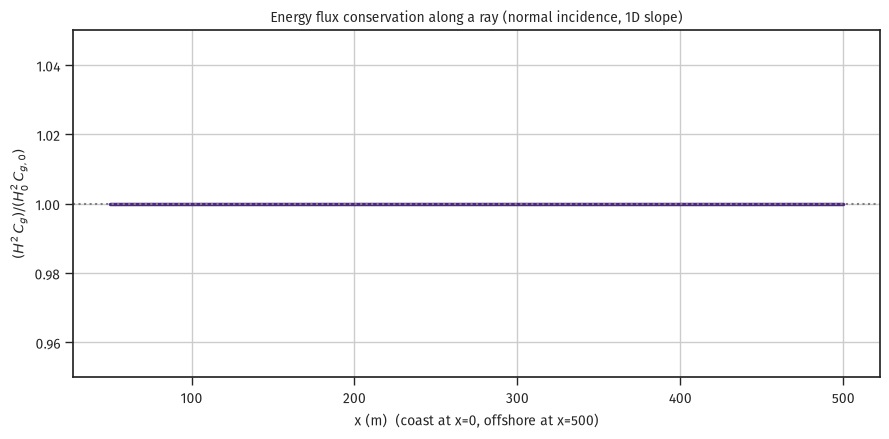

energy-flux ratio, min = 1.0000, max = 1.0000


In [5]:
# 1D sloping bottom, h(x) = 100 (x/L), m
L_slope = 500.0
xs = np.linspace(50, 500, 100)
hs = 100.0 * (xs / L_slope)

H0 = 2.0
T = 10.0
omega = 2*np.pi/T

H_along = np.zeros_like(xs)
for i, h in enumerate(hs):
    r = inshore(T, H0, theta0_deg=0.0, h=h)
    H_along[i] = r['H']

# E Cg is proportional to H^2 Cg, since E = rho g H^2 / 8
Cg_along = np.zeros_like(xs)
for i, h in enumerate(hs):
    r = inshore(T, H0, 0.0, h)
    Cg_along[i] = r['Cg']

ECg = H_along**2 * Cg_along

# Deep-water reference E0 Cg0 = H0^2 g T / (4 pi)
ECg0 = H0**2 * (g*T/(4*np.pi))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(xs, ECg/ECg0, lw=2.5, color=fs.color_list[0])
ax.axhline(1.0, ls=':', color='0.5')
ax.set_xlabel('x (m)  (coast at x=0, offshore at x=500)')
ax.set_ylabel(r'$(H^2\,C_g) / (H_0^2\,C_{g,0})$')
ax.set_title('Energy flux conservation along a ray (normal incidence, 1D slope)')
ax.set_ylim(0.95, 1.05)
plt.tight_layout()
plt.show()

print(f'energy-flux ratio, min = {(ECg/ECg0).min():.4f}, max = {(ECg/ECg0).max():.4f}')

Flat to four decimal places, so the recipe is self-consistent.

## 5. Exercises

1. Work through Example 4.1 from D&D by hand, then verify with `inshore()`. Take a deep-water swell: $T = 12\,$s, $H_0 = 1.5\,$m, incidence angle $\theta_0 = 45°$. Compute the wave at $h = 5\,$m. Does $K_s K_r$ exceed 1? At what angle does the wave reach the breakpoint (using the McCowan criterion $H_b/h_b \approx 0.78$)?

2. Run `inshore()` for $\theta_0 = 0°$, $20°$, $40°$, and $60°$ at fixed $T$ and $H_0$. Plot $H(h)$ for all four on one figure. At which incidence angle is the offshore dip in $H$ deepest, and why? Does the breaking depth move much?

3. Take the ray tracer and replace the headland bump with a submarine canyon (a Gaussian depression instead of a rise). Trace a fan of rays across it. Where does the energy go? What does that say about siting a marina behind a canyon rather than behind a shoal?

## Looking ahead

Week 9: diffraction (waves bending into the shadow of a breakwater), reflection (standing waves, basin seiches), and breaking (the last process where linear theory needs help).